# Chapter 73: Property Rights, Transaction Costs, and the Coasean Framework

This notebook reruns four worked examples from the chapter: Coase bargaining over a night drone route, a corrective charge for smoke damage, ownership and hold-up with two investors, and the make-or-buy choice under transaction costs. Every example is hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def tie_or_winner(a_name, a_value, b_name, b_value, tol=1e-9, higher_wins=True):
    """Return (winner or 'tie', is_tie). Ties within ``tol`` are reported honestly."""
    if abs(float(a_value) - float(b_value)) <= tol:
        return "tie", True
    a_better = a_value > b_value if higher_wins else a_value < b_value
    return (a_name if a_better else b_name), False


def coase_outcome(profit, harm, right, tcost=0.0):
    """Coase bargain over one activity (operate earns profit, imposes harm).

    right is "fly" (operator may operate) or "quiet" (resident may stop it). A bargain moves away
    from the baseline only if its joint gain exceeds the transaction cost tcost; a tie leaves the
    baseline. Principle: coase-theorem. Book (ch073): 140 - 85 = 55 (operate efficient), payment
    range 85 to 140, at 100 the operator keeps 40 and the resident nets 15; harm 170 gives a
    shutdown gain of 30, which cannot cover a 40 transaction cost under a right to fly.
    """
    joint = profit - harm
    efficient = "operate" if joint > 0 else ("shut down" if joint < 0 else "tie")
    baseline = "operate" if right == "fly" else "shut down"
    gain = (-joint) if baseline == "operate" else joint
    trade = gain > tcost
    outcome = baseline if not trade else ("shut down" if baseline == "operate" else "operate")
    if baseline == "operate":
        lo, hi = profit, harm
    else:
        lo, hi = harm, profit
    return {"joint": joint, "efficient": efficient, "baseline": baseline, "bargain_gain": gain, "trade": trade,
            "outcome": outcome, "pay_lo": lo, "pay_hi": hi,
            "is_efficient": efficient == "tie" or outcome == efficient}


def discrete_externality(price, mc_list, damage, tax=0.0):
    """Whole-unit producer with constant per-unit damage and a per-unit charge.

    The producer makes every unit with mc + tax < price (a unit at exactly price is not made).
    W(q) = q price - sum of the first q costs - q damage. Principle: externalities. Book (ch073):
    price 40, mc 10, 18, 26, 34, 42, damage 9: private choice 4, social margins 21, 13, 5, -3,
    W(3) = 120 - 54 - 27 = 39, W(4) = 160 - 88 - 36 = 36; a charge of 9 gives 3 units.
    """
    mcs = [float(m) for m in mc_list]
    chosen = sum(1 for m in mcs if m + tax < price)
    private_q = sum(1 for m in mcs if m < price)
    efficient_q = sum(1 for m in mcs if m + damage < price)

    def welfare(q):
        return q * price - sum(mcs[:q]) - q * damage

    return {"chosen": chosen, "private_q": private_q, "efficient_q": efficient_q,
            "social_margins": [price - m - damage for m in mcs], "W": [welfare(q) for q in range(len(mcs) + 1)],
            "W_chosen": welfare(chosen), "W_efficient": welfare(efficient_q),
            "loss": welfare(efficient_q) - welfare(chosen), "cost_chosen": sum(mcs[:chosen]),
            "damage_chosen": chosen * damage, "revenue": chosen * tax}


def holdup(theta, alpha_a, alpha_b):
    """Two non-verifiable investments with costs a^2/2 and b^2/2; each party keeps a share of its
    marginal contribution theta, so a = alpha_A theta and b = alpha_B theta.

    Net surplus theta a + theta b - a^2/2 - b^2/2; first best a = b = theta.
    Principle: incomplete-contracts. Book (ch073): theta 8: first best 64; shares 0.5 and 0.5 give
    a = b = 4 and 48; shares 0.75 and 0.25 give a = 6, b = 2 and 44.
    """
    a, b = alpha_a * theta, alpha_b * theta
    net = theta * a + theta * b - a * a / 2 - b * b / 2
    first = theta * theta
    return {"a": a, "b": b, "net": net, "first_best": first, "shortfall": first - net}


def governance_cost(components):
    """Sum of a governance option's cost components (dict of name to cost).

    Principle: transaction-costs. Book (ch073): market 2,160 + 150 + 360 + 220 + 520 = 3,410;
    firm 2,640 + 260 + 170 + 220 = 3,290; market with drafting 80 and adaptation 160: 2,770.
    """
    return float(sum(components.values()))


plt.rcParams.update(HOUSE_RC)


public = SimpleNamespace(coase_outcome=coase_outcome, discrete_externality=discrete_externality)


industrial = SimpleNamespace(holdup=holdup)


production = SimpleNamespace(governance_cost=governance_cost)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'coase-theorem': {'profit': 140,
                   'harm': 85,
                   'joint': 55,
                   'payment': 100,
                   'operator_keeps': 40,
                   'resident_nets': 15,
                   'harm_2': 170,
                   'shutdown_gain': 30,
                   'tcost': 40},
 'externalities': {'price': 40,
                   'mc': [10, 18, 26, 34, 42],
                   'damage': 9,
                   'smc': [19, 27, 35, 43, 51],
                   'margins': [21, 13, 5, -3],
                   'private_q': 4,
                   'efficient_q': 3,
                   'W3': 39,
                   'W4': 36,
                   'gain': 3},
 'incomplete-contracts': {'theta': 8,
                          'first_best': 64,
                          'a_bal': 4,
                          'b_bal': 4,
                          'net_bal': 48,
                          'a_own': 6,
                          'b_own': 2,
                          'net_own': 44},
 'transaction-costs': {'units': 120,
                       'price': 18,
                       'market': {'production': 2160,
                                  'search': 150,
                                  'drafting': 360,
                                  'monitoring': 220,
                                  'adaptation': 520},
                       'firm': {'production': 2640,
                                'management': 260,
                                'measurement': 170,
                                'rigidity': 220},
                       'TC_M': 3410,
                       'TC_F': 3290,
                       'saving': 120,
                       'drafting_2': 80,
                       'adaptation_2': 160,
                       'TC_M_2': 2770,
                       'outsourcing_saving': 520},
 'constructed': {'coase-theorem': {'harm': [120]},
                 'externalities': {'damage': [0, 5, 15], 'tax': [15]},
                 'incomplete-contracts': {'alpha_a': [0.25]},
                 'transaction-costs': {'drafting': [220], 'adaptation': [340, 700]}}}


def _bar_values(ax, xs, vals, fmt, size=10.5):
    for x, v in zip(xs, vals):
        ax.annotate(fmt(v), (x, v), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom",
                    fontsize=size, color=PALETTE["ink"], zorder=6,
                    bbox={"boxstyle": "round,pad=0.15", "fc": "white", "ec": "none", "alpha": 0.9})


def coase_picture(h=85, right="fly", k=0):
    profit = BV["coase-theorem"]["profit"]
    r = public.coase_outcome(profit, h, right, k)
    fig, ax = new_figure()
    ax.bar([0, 1], [profit, h], color=[PALETTE["teal"], PALETTE["terracotta"]], width=0.5)
    _bar_values(ax, [0, 1], [profit, h], lambda v: num(v, 0))
    if r["bargain_gain"] > 0:
        lo, hi = r["pay_lo"], r["pay_hi"]
        ax.axhspan(lo, hi, color=PALETTE["gold"], alpha=0.22)
        who = "operator pays the resident" if r["baseline"] == "shut down" else "resident pays the operator"
        tail = "" if r["trade"] else f";\nthe {k} cost of bargaining exceeds the {num(r['bargain_gain'], 0)} gain"
        ax.text(0.02, 0.84, f"gold band: payments both would accept, {num(lo, 0)} to {num(hi, 0)}\n({who}{tail})",
                transform=ax.transAxes, ha="left", va="top", fontsize=10.5, color=PALETTE["gold"])
    ax.set_xticks([0, 1], ["operator's profit", "resident's harm"])
    ax.set_xlim(-0.5, 1.5)
    ax.set_ylim(0, 260)
    ax.set_ylabel("Value of the night route")
    ax.set_xlabel("Party")
    right_text = "a right to fly" if right == "fly" else "a right to quiet"
    ax.text(0.02, 0.97, f"Holder: {right_text}; bargaining cost {k}\nOutcome: route "
            f"{'operates' if r['outcome'] == 'operate' else 'shuts down'} "
            f"({'efficient' if r['is_efficient'] else 'inefficient'})", transform=ax.transAxes, ha="left", va="top",
            fontsize=10.5, color=PALETTE["ink"])
    joint = r["joint"]
    if joint > 0:
        eff = f"Operating is efficient: {profit} - {h} = {num(joint, 0)}."
    elif joint < 0:
        eff = f"Shutdown is efficient: {h} - {profit} = {num(-joint, 0)} more joint value than operating."
    else:
        eff = f"Operating and shutdown tie: {profit} - {h} = 0."
    base = "the route operates" if r["baseline"] == "operate" else "the route is shut down"
    if r["bargain_gain"] <= 0:
        move = f"With {right_text} the baseline is that {base}, which is already efficient, so no trade is needed."
    elif r["trade"]:
        move = (f"With {right_text} the baseline is that {base}. Changing it gains {num(r['bargain_gain'], 0)}, "
                f"which covers the bargaining cost of {k}, so a payment between {num(r['pay_lo'], 0)} and "
                f"{num(r['pay_hi'], 0)} moves the route to the efficient outcome.")
    else:
        move = (f"With {right_text} the baseline is that {base}. Changing it would gain "
                f"{num(r['bargain_gain'], 0)}, but {num(r['bargain_gain'], 0)} - {k} = "
                f"{num(r['bargain_gain'] - k, 0)} is not positive, so no bargain happens and the inefficient "
                f"baseline stays.")
    split = ""
    if r["trade"] and r["baseline"] == "shut down" and r["pay_lo"] <= 100 <= r["pay_hi"]:
        split = (f" At the book's payment of 100 the operator keeps {profit} - 100 = {profit - 100} and the resident "
                 f"nets 100 - {h} = {100 - h}.")
    interp = f"{eff} {move}{split}"
    metrics = {"Joint surplus from operating": num(joint, 0),
               "Efficient outcome": {"operate": "Operate", "shut down": "Shut down", "tie": "Tie"}[r["efficient"]],
               "Baseline under the right": "Operate" if r["baseline"] == "operate" else "Shut down",
               "Gain from bargaining away from it": num(max(r["bargain_gain"], 0), 0),
               "Final outcome": "Operate" if r["outcome"] == "operate" else "Shut down",
               "Efficient?": "Yes" if r["is_efficient"] else "No"}
    steps = [f"Joint surplus from operating = {profit} - {h} = {num(joint, 0)}",
             f"Baseline with {right_text}: {base}",
             (f"Gain from changing the baseline = {num(r['bargain_gain'], 0)}, against a bargaining cost of {k}"
              if r["bargain_gain"] > 0 else "The baseline is already efficient, so there is nothing to buy"),
             f"Outcome: route {'operates' if r['outcome'] == 'operate' else 'shuts down'}"]
    alt = (f"Bars for the operator's profit {profit} and the resident's harm {h}. With {right_text} and a bargaining "
           f"cost of {k}, the route {'operates' if r['outcome'] == 'operate' else 'shuts down'}, which is "
           f"{'efficient' if r['is_efficient'] else 'inefficient'}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def smoke_picture(d=9, tax=9):
    bv = BV["externalities"]
    price, mcs = bv["price"], bv["mc"]
    r = public.discrete_externality(price, mcs, d, tax)
    units = np.arange(1, 6)
    fig, ax = new_figure()
    w = 0.26
    ax.bar(units - w, mcs, width=w, color=PALETTE["light"], label="private marginal cost")
    ax.bar(units, [m + tax for m in mcs], width=w, color=PALETTE["navy"], label="cost the producer faces")
    ax.bar(units + w, [m + d for m in mcs], width=w, color=PALETTE["terracotta"], label="social marginal cost")
    ax.axhline(price, color=PALETTE["gold"], linewidth=2)
    ax.text(0.6, price + 1.2, f"price {price}", ha="left", va="bottom", fontsize=10.5, color=PALETTE["gold"])
    if r["chosen"] > 0:
        ax.axvline(r["chosen"] + 0.5, color=PALETTE["ink"], linestyle="dashed", linewidth=1.3)
    ax.set_xticks(units)
    ax.set_xlim(0.4, 5.6)
    ax.set_ylim(0, 92)
    ax.legend(loc="upper left", frameon=False)
    ax.set_xlabel(f"Unit (dashed line: the producer stops after unit {r['chosen']})")
    ax.set_ylabel("Cost or price per unit")
    q, qe = r["chosen"], r["efficient_q"]
    costs = " + ".join(str(m) for m in mcs[:q]) if q else "0"
    W = r["W_chosen"]
    metrics = {"Units made under the charge": str(q), "Efficient quantity": str(qe),
               "Welfare at the chosen quantity": num(W, 0), "Welfare at the efficient quantity": num(r["W_efficient"], 0),
               "Loss from the wrong quantity": num(r["loss"], 0), "Charge revenue": num(r["revenue"], 0)}
    margins = ", ".join(num(v, 0) for v in r["social_margins"])
    steps = [f"Social margins 40 - (cost + {d}) for units 1 to 5: {margins}",
             f"Efficient quantity: every unit with a positive margin, so {qe}",
             f"The producer faces cost + {tax} and makes every unit below 40: {q}",
             f"W({q}) = {q} x 40 - ({costs}) - {q} x {d} = {num(q * price, 0)} - {num(r['cost_chosen'], 0)} - "
             f"{num(r['damage_chosen'], 0)} = {num(W, 0)}"]
    if q == qe:
        verdict = f"The charge of {tax} makes the producer stop at the efficient {qe} units, so no surplus is lost."
    elif q > qe:
        verdict = (f"The charge of {tax} is below the damage of {d}, so the producer makes {q} units, "
                   f"{q - qe} more than the efficient {qe}, losing {num(r['loss'], 0)}.")
    else:
        verdict = (f"The charge of {tax} exceeds the damage of {d}, so the producer makes only {q} units, "
                   f"{qe - q} fewer than the efficient {qe}, losing {num(r['loss'], 0)}.")
    interp = (f"With damage {d} per unit, social marginal costs are private costs plus {d}. "
              f"W({q}) = {num(q * price, 0)} - {num(r['cost_chosen'], 0)} - {num(r['damage_chosen'], 0)} = "
              f"{num(W, 0)}, against {num(r['W_efficient'], 0)} at the efficient quantity. {verdict}")
    alt = (f"Bars for units 1 to 5: private cost, cost including the charge of {tax}, and social cost with damage "
           f"{d}, against a price line at 40. The producer makes {q} units; the efficient quantity is {qe}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def holdup_picture(a_share=0.50, b_share=0.50):
    theta = BV["incomplete-contracts"]["theta"]
    r = industrial.holdup(theta, a_share, b_share)
    fig, (ax, ax2) = new_figure(2)
    ax.bar([0, 1], [r["a"], r["b"]], color=[PALETTE["teal"], PALETTE["navy"]], width=0.5)
    _bar_values(ax, [0, 1], [r["a"], r["b"]], lambda v: num(v, 0))
    ax.axhline(theta, color=PALETTE["grey"], linestyle="dashed", linewidth=1.3)
    ax.text(0.5, theta + 0.15, f"first best {theta}", ha="center", va="bottom", fontsize=10.5, color=PALETTE["grey"])
    ax.set_xticks([0, 1], ["A's investment a", "B's investment b"])
    ax.set_xlim(-0.5, 1.5)
    ax.set_ylim(0, 10)
    ax.set_ylabel("Investment")
    ax.set_xlabel(f"Shares kept: A {num(a_share)}, B {num(b_share)}")
    ax2.bar([0], [r["net"]], color=PALETTE["gold"], width=0.45)
    _bar_values(ax2, [0], [r["net"]], lambda v: num(v, 0))
    ax2.axhline(r["first_best"], color=PALETTE["grey"], linestyle="dashed", linewidth=1.3)
    ax2.text(0.45, r["first_best"] + 0.8, f"first best {num(r['first_best'], 0)}", ha="right", va="bottom",
             fontsize=10.5, color=PALETTE["grey"])
    ax2.set_xticks([0], ["total net surplus"])
    ax2.set_xlim(-0.5, 0.5)
    ax2.set_ylim(0, 75)
    ax2.set_ylabel("Net surplus")
    ax2.set_xlabel("Both parties together")
    a, b, net = r["a"], r["b"], r["net"]
    metrics = {"A's investment a": num(a, 0), "B's investment b": num(b, 0), "Total net surplus": num(net, 0),
               "First-best surplus": num(r["first_best"], 0), "Shortfall from first best": num(r["shortfall"], 0)}
    calc = (f"8({num(a, 0)}) + 8({num(b, 0)}) - {num(a, 0)}^2/2 - {num(b, 0)}^2/2 = {num(8 * a, 0)} + "
            f"{num(8 * b, 0)} - {num(a * a / 2)} - {num(b * b / 2)} = {num(net, 0)}")
    steps = [f"a = {num(a_share)} x 8 = {num(a, 0)}", f"b = {num(b_share)} x 8 = {num(b, 0)}",
             f"Net surplus = {calc}",
             f"Shortfall = {num(r['first_best'], 0)} - {num(net, 0)} = {num(r['shortfall'], 0)}"]
    if r["shortfall"] < 1e-9:
        note = "Each party keeps its full marginal return, so both invest the first-best 8."
    else:
        note = ("A party that keeps only part of its marginal return invests less than 8, and each shortfall in "
                "investment costs surplus.")
    interp = (f"A keeps {num(a_share)} and B keeps {num(b_share)} of their marginal contributions, so a = "
              f"{num(a_share)} x 8 = {num(a, 0)} and b = {num(b_share)} x 8 = {num(b, 0)}. Net surplus is {calc}, "
              f"{num(r['shortfall'], 0)} below the first-best {num(r['first_best'], 0)}. {note} Ownership is judged "
              f"by total surplus, not by the owner's response alone.")
    alt = (f"Left: investments a = {num(a, 0)} and b = {num(b, 0)} against the first-best 8. Right: total net "
           f"surplus {num(net, 0)} against the first-best {num(r['first_best'], 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def governance_picture(draft=360, adapt=520):
    bv = BV["transaction-costs"]
    market = dict(bv["market"], drafting=draft, adaptation=adapt)
    firm = dict(bv["firm"])
    tm, tf = production.governance_cost(market), production.governance_cost(firm)
    winner, tie = tie_or_winner("market", tm, "firm", tf, higher_wins=False)
    groups = [
        ("physical production", [market["production"], firm["production"]], "light"),
        ("search, drafting, monitoring / management, measurement",
         [market["search"] + market["drafting"] + market["monitoring"], firm["management"] + firm["measurement"]],
         "navy"),
        ("adaptation / delay and rigidity", [market["adaptation"], firm["rigidity"]], "terracotta"),
    ]
    fig, ax = new_figure()
    base = np.zeros(2)
    for lab, vals, col in groups:
        ax.bar([0, 1], vals, bottom=base, color=PALETTE[col], width=0.5, label=lab)
        base = base + np.array(vals, dtype=float)
    _bar_values(ax, [0, 1], [tm, tf], lambda v: num(v, 0))
    ax.set_xticks([0, 1], ["Buy from the market", "Make inside the firm"])
    ax.set_xlim(-0.5, 1.5)
    ax.set_ylim(0, 5200)
    ax.legend(loc="upper left", frameon=False, fontsize=10)
    ax.set_ylabel("Total governance cost")
    ax.set_xlabel("Governance of 120 components")
    gap = abs(tm - tf)
    metrics = {"Market cost TC_M": num(tm, 0), "Firm cost TC_F": num(tf, 0),
               "Cheaper governance": "Tie" if tie else ("Buy (market)" if winner == "market" else "Make (firm)"),
               "Saving from the cheaper option": num(gap, 0)}
    steps = [f"TC_M = 2,160 + 150 + {num(draft, 0)} + 220 + {num(adapt, 0)} = {num(tm, 0)}",
             f"TC_F = 2,640 + 260 + 170 + 220 = {num(tf, 0)}",
             (f"Gap = {num(max(tm, tf), 0)} - {num(min(tm, tf), 0)} = {num(gap, 0)}")]
    if tie:
        verdict = "The two options cost the same, so governance cost alone does not decide."
    elif winner == "firm":
        verdict = (f"Making inside the firm saves {num(gap, 0)}, even though its physical production costs 480 "
                   f"more, because outside contracting is expensive.")
    else:
        verdict = (f"Buying from the market saves {num(gap, 0)}: with drafting at {num(draft, 0)} and adaptation at "
                   f"{num(adapt, 0)}, contracting costs no longer outweigh the outside supplier's 480 lower "
                   f"production cost.")
    interp = (f"TC_M = 2,160 + 150 + {num(draft, 0)} + 220 + {num(adapt, 0)} = {num(tm, 0)} and TC_F = "
              f"{num(tf, 0)}. {verdict} The component did not change; only the cost of governing the exchange did.")
    alt = (f"Stacked bars of governance cost: buying from the market costs {num(tm, 0)} with drafting {num(draft, 0)} "
           f"and adaptation {num(adapt, 0)}; making inside the firm costs {num(tf, 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Coase theorem: bargaining over a night drone route

The route earns 140 and disturbs a resident by 85, so operating creates

$$140-85=55$$

With a right to quiet and a payment of 100, the operator keeps $140-100=40$ and the resident nets $100-85=15$.

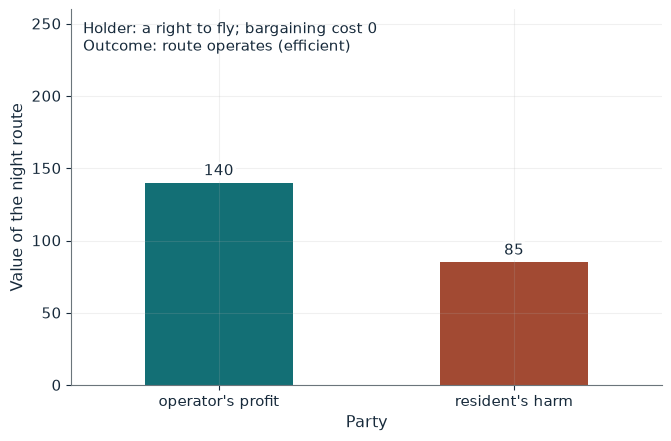

Joint surplus from operating       55
Efficient outcome                  Operate
Baseline under the right           Operate
Gain from bargaining away from it  0
Final outcome                      Operate
Efficient?                         Yes

Worked steps:
  1. Joint surplus from operating = 140 - 85 = 55
  2. Baseline with a right to fly: the route operates
  3. The baseline is already efficient, so there is nothing to buy
  4. Outcome: route operates

Operating is efficient: 140 - 85 = 55. With a right to fly the baseline is that the route operates, which is already efficient, so no trade is needed.


In [2]:
show(coase_picture(h=85, right='fly', k=0))

Change one input, `h`, and hold the others at the book's values:

In [3]:
sweep(coase_picture, 'h', [85, 120, 170], {'right': 'fly', 'k': 40}, ['Efficient outcome', 'Final outcome', 'Efficient?'])

h | Efficient outcome | Final outcome | Efficient?
85 | Operate | Operate | Yes
120 | Operate | Operate | Yes
170 | Shut down | Operate | No


With costless bargaining the route operates under either right. With harm 170, a right to fly and a bargaining cost of 40, shutdown would gain only 30, so the inefficient route keeps operating.

## 2. Externalities: smoke damage and the corrective charge

Price is 40, private marginal costs are 10, 18, 26, 34 and 42, and each unit causes damage 9.

$$40-19=21,\qquad 40-27=13,\qquad 40-35=5$$

$$W(3)=120-54-27=39, \qquad W(4)=160-88-36=36$$

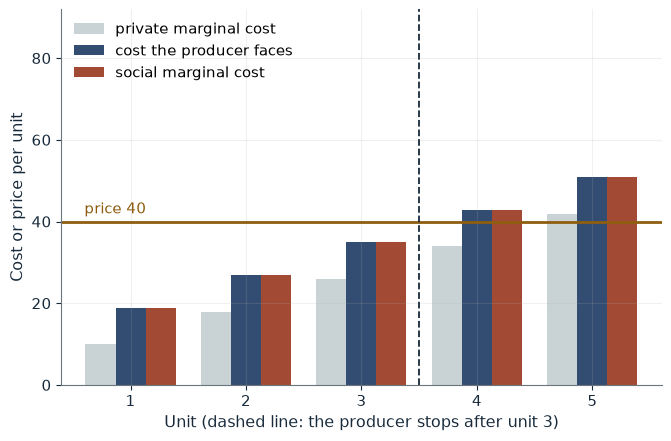

Units made under the charge        3
Efficient quantity                 3
Welfare at the chosen quantity     39
Welfare at the efficient quantity  39
Loss from the wrong quantity       0
Charge revenue                     27

Worked steps:
  1. Social margins 40 - (cost + 9) for units 1 to 5: 21, 13, 5, -3, -11
  2. Efficient quantity: every unit with a positive margin, so 3
  3. The producer faces cost + 9 and makes every unit below 40: 3
  4. W(3) = 3 x 40 - (10 + 18 + 26) - 3 x 9 = 120 - 54 - 27 = 39

With damage 9 per unit, social marginal costs are private costs plus 9. W(3) = 120 - 54 - 27 = 39, against 39 at the efficient quantity. The charge of 9 makes the producer stop at the efficient 3 units, so no surplus is lost.


In [4]:
show(smoke_picture(d=9, tax=9))

Change one input, `tax`, and hold the others at the book's values:

In [5]:
sweep(smoke_picture, 'tax', [0, 9, 15], {'d': 9}, ['Units made under the charge', 'Welfare at the chosen quantity', 'Loss from the wrong quantity'])

tax | Units made under the charge | Welfare at the chosen quantity | Loss from the wrong quantity
0 | 4 | 36 | 3
9 | 3 | 39 | 0
15 | 2 | 34 | 5


Without a charge the producer makes 4 units and welfare is 36; a charge of 9 brings output to the efficient 3 units and welfare to 39. A charge of 15 overshoots to 2 units.

## 3. Incomplete contracts: ownership and hold-up

Each unit of investment adds 8, and costs are

$$c_A(a)=\frac{a^2}{2},\qquad c_B(b)=\frac{b^2}{2}$$

With shares 0.75 and 0.25,

$$8(6)+8(2)-\frac{6^2}{2}-\frac{2^2}{2}=44$$

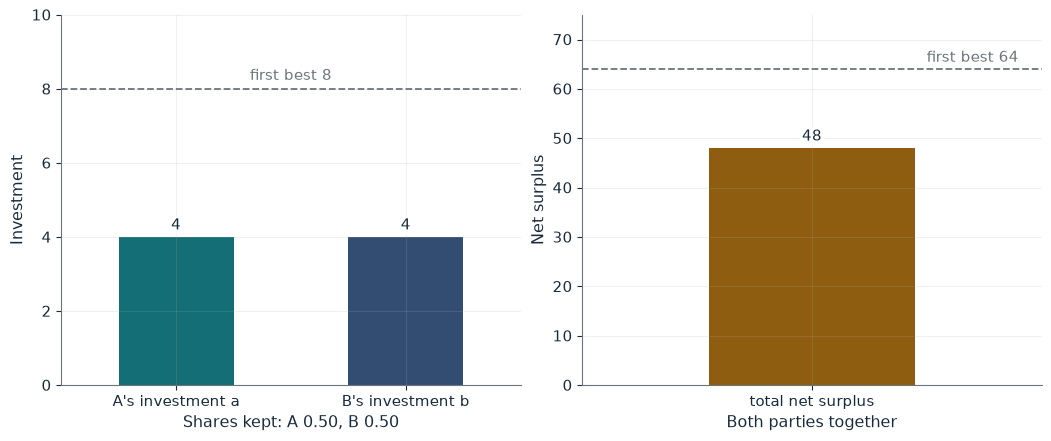

A's investment a           4
B's investment b           4
Total net surplus          48
First-best surplus         64
Shortfall from first best  16

Worked steps:
  1. a = 0.50 x 8 = 4
  2. b = 0.50 x 8 = 4
  3. Net surplus = 8(4) + 8(4) - 4^2/2 - 4^2/2 = 32 + 32 - 8.00 - 8.00 = 48
  4. Shortfall = 64 - 48 = 16

A keeps 0.50 and B keeps 0.50 of their marginal contributions, so a = 0.50 x 8 = 4 and b = 0.50 x 8 = 4. Net surplus is 8(4) + 8(4) - 4^2/2 - 4^2/2 = 32 + 32 - 8.00 - 8.00 = 48, 16 below the first-best 64. A party that keeps only part of its marginal return invests less than 8, and each shortfall in investment costs surplus. Ownership is judged by total surplus, not by the owner's response alone.


In [6]:
show(holdup_picture(a_share=0.50, b_share=0.50))

Change one input, `a_share`, and hold the others at the book's values:

In [7]:
sweep(holdup_picture, 'a_share', [0.25, 0.5, 0.75, 1.0], {'b_share': 0.25}, ["A's investment a", "B's investment b", 'Total net surplus'])

a_share | A's investment a | B's investment b | Total net surplus
0.25 | 2 | 2 | 28
0.5 | 4 | 2 | 38
0.75 | 6 | 2 | 44
1.0 | 8 | 2 | 46


Balanced shares give a = b = 4 and surplus 48. Moving the asset to A (0.75 and 0.25) raises a to 6 but cuts b to 2, and surplus falls to 44.

## 4. Transaction costs: make or buy

Buying 120 components and making them cost

$$TC_M=2{,}160+150+360+220+520=3{,}410, \qquad TC_F=2{,}640+260+170+220=3{,}290$$

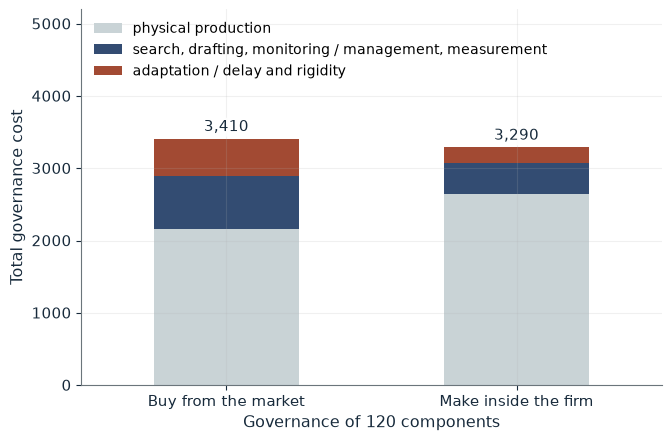

Market cost TC_M                3,410
Firm cost TC_F                  3,290
Cheaper governance              Make (firm)
Saving from the cheaper option  120

Worked steps:
  1. TC_M = 2,160 + 150 + 360 + 220 + 520 = 3,410
  2. TC_F = 2,640 + 260 + 170 + 220 = 3,290
  3. Gap = 3,410 - 3,290 = 120

TC_M = 2,160 + 150 + 360 + 220 + 520 = 3,410 and TC_F = 3,290. Making inside the firm saves 120, even though its physical production costs 480 more, because outside contracting is expensive. The component did not change; only the cost of governing the exchange did.


In [8]:
show(governance_picture(draft=360, adapt=520))

Change one input, `adapt`, and hold the others at the book's values:

In [9]:
sweep(governance_picture, 'adapt', [160, 340, 520, 700], {'draft': 80}, ['Market cost TC_M', 'Cheaper governance', 'Saving from the cheaper option'])

adapt | Market cost TC_M | Cheaper governance | Saving from the cheaper option
160 | 2,770 | Buy (market) | 520
340 | 2,950 | Buy (market) | 340
520 | 3,130 | Buy (market) | 160
700 | 3,310 | Make (firm) | 20


Integration saves 120 at the book's costs. A template that cuts drafting to 80 and adaptation to 160 brings $TC_M'$ to 2,770, so buying becomes 520 cheaper.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

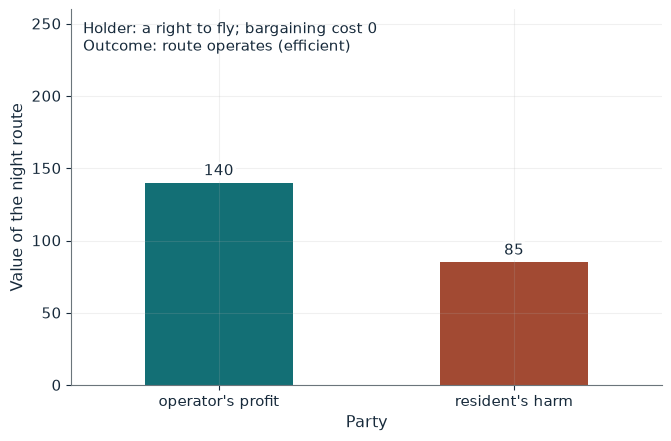

Joint surplus from operating       55
Efficient outcome                  Operate
Baseline under the right           Operate
Gain from bargaining away from it  0
Final outcome                      Operate
Efficient?                         Yes

Worked steps:
  1. Joint surplus from operating = 140 - 85 = 55
  2. Baseline with a right to fly: the route operates
  3. The baseline is already efficient, so there is nothing to buy
  4. Outcome: route operates

Operating is efficient: 140 - 85 = 55. With a right to fly the baseline is that the route operates, which is already efficient, so no trade is needed.


In [10]:
show(coase_picture(h=85, right='fly', k=0))

## Practice

**1.** With harm 170, what is the gain from shutdown, and can it cover a 40 transaction cost?

<details><summary>Answer</summary>

170 - 140 = 30, less than 40, so with a right to fly the route keeps operating.

</details>

**2.** With no charge and damage 9, what is welfare at the private choice?

<details><summary>Answer</summary>

4 units: W(4) = 160 - 88 - 36 = 36.

</details>

**3.** What is TC_M with drafting 80 and adaptation 160?

<details><summary>Answer</summary>

2,160 + 150 + 80 + 220 + 160 = 2,770, which is 520 below TC_F = 3,290.

</details>